In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("RetailPulse - Day 6: Demand Forecasting")
print("Environment ready")


RetailPulse - Day 6: Demand Forecasting
Environment ready


In [2]:
file_path = Path("../data/processed/retail_cleaned.csv")

if not file_path.exists():
    file_path = Path("E:/data/processed/retail_cleaned.csv")

df = pd.read_csv(file_path, parse_dates=["InvoiceDate"])

print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

C:\Users\DRT-Admin\AppData\Local\Temp\ipykernel_19972\2693311380.py:6: DtypeWarning: Columns (0: Invoice) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path, parse_dates=["InvoiceDate"])


Dataset Shape: (1007913, 8)
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:
df["Revenue"] = df["Quantity"] * df["Price"]

monthly_sales = (
    df[df["Quantity"] > 0]
    .groupby(pd.Grouper(key="InvoiceDate", freq="MS"))["Quantity"]
    .sum()
    .reset_index()
)

monthly_sales.columns = ["Month", "Demand"]
monthly_sales = monthly_sales.sort_values("Month")

print(monthly_sales.tail(12))

        Month  Demand
13 2011-01-01  387099
14 2011-02-01  282934
15 2011-03-01  376599
16 2011-04-01  307953
17 2011-05-01  395001
18 2011-06-01  388511
19 2011-07-01  399693
20 2011-08-01  421020
21 2011-09-01  569573
22 2011-10-01  621029
23 2011-11-01  751377
24 2011-12-01  313613


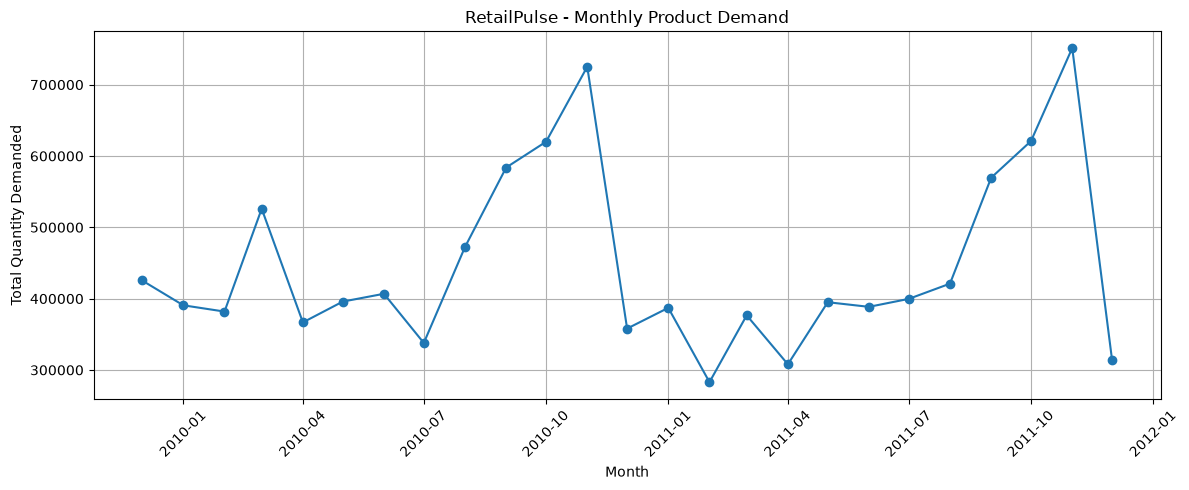

In [4]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["Demand"],
    marker="o"
)

plt.title("RetailPulse - Monthly Product Demand")
plt.xlabel("Month")
plt.ylabel("Total Quantity Demanded")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [5]:
monthly_sales["3_Month_MA"] = (
    monthly_sales["Demand"]
    .rolling(window=3)
    .mean()
)

monthly_sales["6_Month_MA"] = (
    monthly_sales["Demand"]
    .rolling(window=6)
    .mean()
)

print(monthly_sales.tail(12))

        Month  Demand     3_Month_MA     6_Month_MA
13 2011-01-01  387099  490093.000000  524419.833333
14 2011-02-01  282934  342684.000000  492845.500000
15 2011-03-01  376599  348877.333333  458301.333333
16 2011-04-01  307953  322495.333333  406294.166667
17 2011-05-01  395001  359851.000000  351267.500000
18 2011-06-01  388511  363821.666667  356349.500000
19 2011-07-01  399693  394401.666667  358448.500000
20 2011-08-01  421020  403074.666667  381462.833333
21 2011-09-01  569573  463428.666667  413625.166667
22 2011-10-01  621029  537207.333333  465804.500000
23 2011-11-01  751377  647326.333333  525200.500000
24 2011-12-01  313613  562006.333333  512717.500000


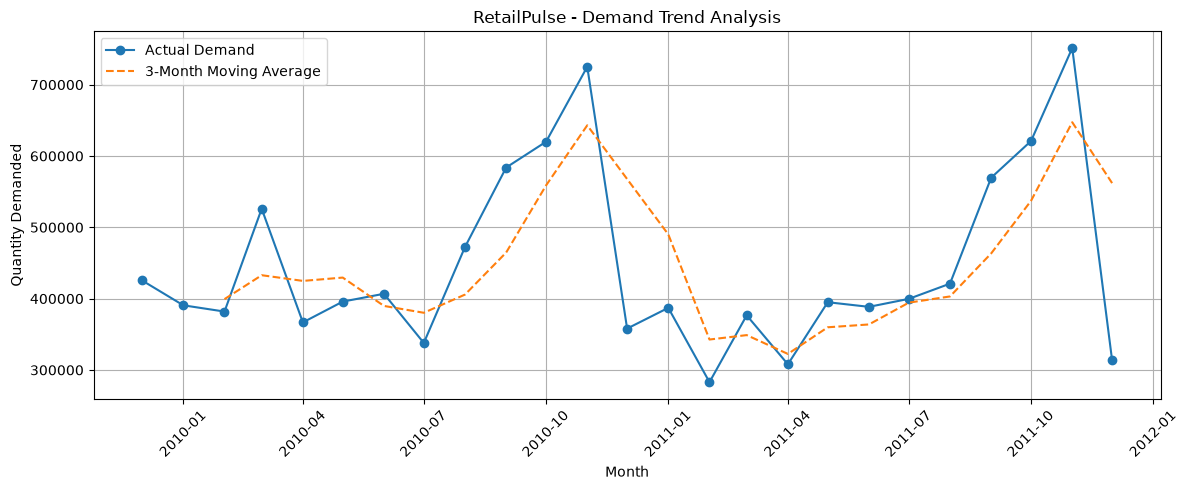

In [7]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["Demand"],
    marker="o",
    label="Actual Demand"
)

plt.plot(
    monthly_sales["Month"],
    monthly_sales["3_Month_MA"],
    linestyle="--",
    label="3-Month Moving Average"
)

plt.title("RetailPulse - Demand Trend Analysis")
plt.xlabel("Month")
plt.ylabel("Quantity Demanded")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
last_date = monthly_sales["Month"].max()
last_3_month_avg = monthly_sales["Demand"].tail(3).mean()

future_dates = pd.date_range(
    start=last_date + pd.offsets.MonthBegin(1),
    periods=3,
    freq="MS"
)

forecast = pd.DataFrame({
    "Month": future_dates,
    "Forecast_Demand": [round(last_3_month_avg, 2)] * 3
})

print("Next 3 Months Baseline Demand Forecast:")
print(forecast)

Next 3 Months Baseline Demand Forecast:
       Month  Forecast_Demand
0 2012-01-01        562006.33
1 2012-02-01        562006.33
2 2012-03-01        562006.33


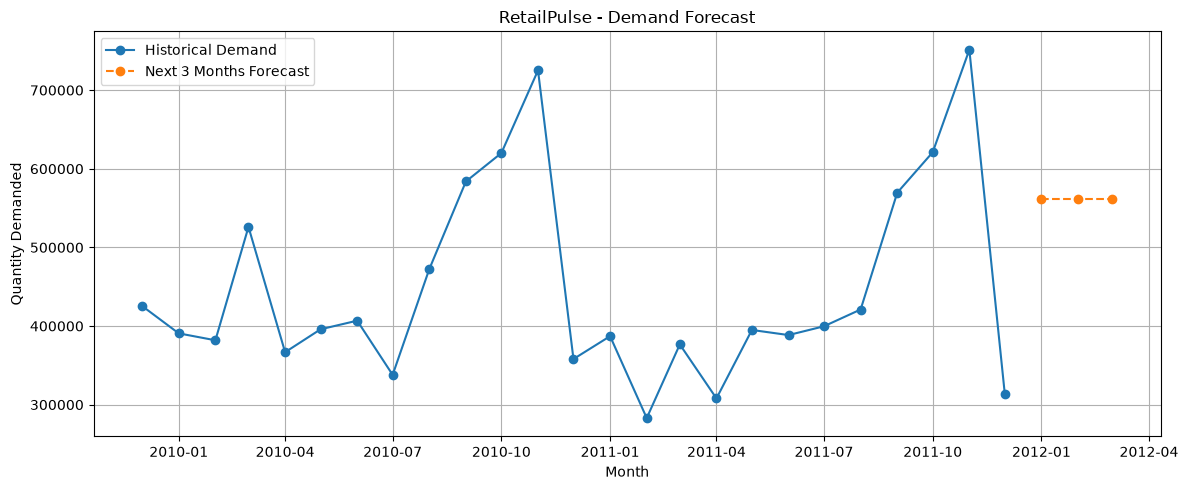

In [9]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["Demand"],
    marker="o",
    label="Historical Demand"
)

plt.plot(
    forecast["Month"],
    forecast["Forecast_Demand"],
    marker="o",
    linestyle="--",
    label="Next 3 Months Forecast"
)

plt.title("RetailPulse - Demand Forecast")
plt.xlabel("Month")
plt.ylabel("Quantity Demanded")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [10]:
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

forecast_file = output_dir / "demand_forecast.csv"
forecast.to_csv(forecast_file, index=False)

print("Forecast saved successfully!")
print("File location:", forecast_file.resolve())

Forecast saved successfully!
File location: E:\data\processed\demand_forecast.csv
